In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None)

cols = ["unit_nr", "time_cycles", "os1", "os2", "os3"] + [
    f"s{i}" for i in range(1, 22)
]
df.columns = cols



In [ ]:
# 2. Select engines
healthy_unit = 1
failing_unit = 34 

df_healthy = df[df["unit_nr"] == healthy_unit]
df_failing = df[df["unit_nr"] == failing_unit]



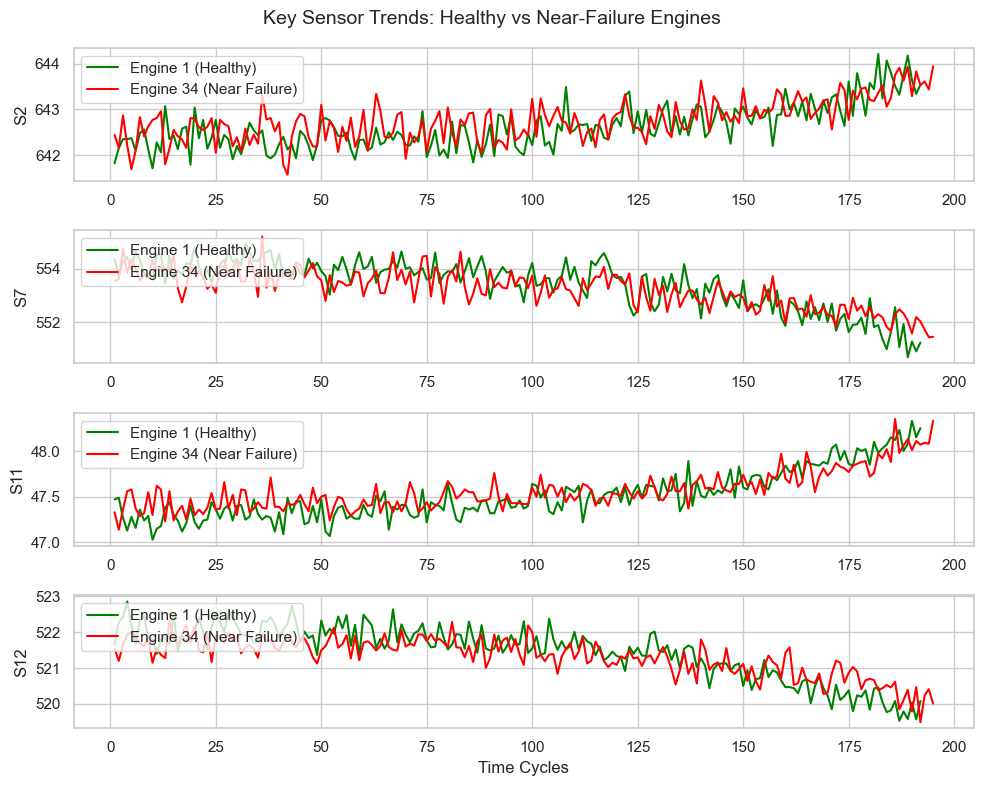

In [ ]:
# 3. Plot key predictive sensors
key_sensors = ["s2", "s7", "s11", "s12"]
fig, axes = plt.subplots(len(key_sensors), 1, figsize=(10, 8), sharex=False)

for idx, sensor in enumerate(key_sensors):
    axes[idx].plot(
        df_healthy["time_cycles"],
        df_healthy[sensor],
        label=f"Engine {healthy_unit} (Healthy)",
        color="green",
    )
    axes[idx].plot(
        df_failing["time_cycles"],
        df_failing[sensor],
        label=f"Engine {failing_unit} (Near Failure)",
        color="red",
    )
    axes[idx].set_ylabel(sensor.upper())
    axes[idx].legend(loc="upper left")

axes[-1].set_xlabel("Time Cycles")
plt.suptitle("Key Sensor Trends: Healthy vs Near-Failure Engines", fontsize=14)
plt.tight_layout()
plt.savefig("sensor_trends.png", dpi=300)
plt.show()